In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest

import joblib

In [2]:
df = pd.read_csv(
    "../dataset/AquaSense_Feature_Engineered.csv"
)

df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (45864, 22)


,Date,Time,Consumption,Temperature,Rain,Sun,Hour,Timestamp,Day,Month,...,Weekday,Hour_sin,Hour_cos,Month_sin,Month_cos,Lag_1,Lag_24,Lag_168,Rolling_Mean_24,Rolling_Mean_168
0,2016-01-08,00:00-01:00,1025,5.5,0.0,0,0,2016-01-08 00:00:00,8,1,...,Friday,0.000000,1.000000,0.5,0.866025,1653.0,1007.0,1480.0,1999.416667,1956.035714
1,2016-01-08,01:00-02:00,605,5.6,0.0,0,1,2016-01-08 01:00:00,8,1,...,Friday,0.258819,0.965926,0.5,0.866025,1025.0,624.0,1362.0,2000.166667,1953.327381
2,2016-01-08,02:00-03:00,358,5.6,0.0,0,2,2016-01-08 02:00:00,8,1,...,Friday,0.500000,0.866025,0.5,0.866025,605.0,384.0,1296.0,1999.375000,1948.821429
3,2016-01-08,03:00-04:00,277,5.4,0.0,0,3,2016-01-08 03:00:00,8,1,...,Friday,0.707107,0.707107,0.5,0.866025,358.0,217.0,1096.0,1998.291667,1943.238095
4,2016-01-08,04:00-05:00,336,5.1,0.0,0,4,2016-01-08 04:00:00,8,1,...,Friday,0.866025,0.500000,0.5,0.866025,277.0,287.0,810.0,2000.791667,1938.363095


In [3]:
anomaly_features = [
    "Consumption",
    "Temperature",
    "Rain",
    "Sun",
    "Hour",
    "DayOfWeek",
    "Lag_1",
    "Lag_24",
    "Rolling_Mean_24",
    "Rolling_Mean_168"
]

X_anomaly = df[anomaly_features]

print("Anomaly Detection Features:", X_anomaly.shape)
display(X_anomaly.head())

Anomaly Detection Features: (45864, 10)


,Consumption,Temperature,Rain,Sun,Hour,DayOfWeek,Lag_1,Lag_24,Rolling_Mean_24,Rolling_Mean_168
0,1025,5.5,0.0,0,0,4,1653.0,1007.0,1999.416667,1956.035714
1,605,5.6,0.0,0,1,4,1025.0,624.0,2000.166667,1953.327381
2,358,5.6,0.0,0,2,4,605.0,384.0,1999.375000,1948.821429
3,277,5.4,0.0,0,3,4,358.0,217.0,1998.291667,1943.238095
4,336,5.1,0.0,0,4,4,277.0,287.0,2000.791667,1938.363095


In [5]:
# Split dataset into training and testing data

split_index = int(len(df) * 0.80)

X_anomaly_train = X_anomaly.iloc[:split_index]
X_anomaly_test = X_anomaly.iloc[split_index:]

print("Training Records:", len(X_anomaly_train))
print("Testing Records:", len(X_anomaly_test))

Training Records: 36691
Testing Records: 9173


In [6]:
print("Training data shape:", X_anomaly_train.shape)
print("Testing data shape:", X_anomaly_test.shape)

Training data shape: (36691, 10)
Testing data shape: (9173, 10)


In [7]:
iso_model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

iso_model.fit(X_anomaly_train)

print("Isolation Forest trained successfully!")

Isolation Forest trained successfully!


In [8]:
# Predict anomalies in the test dataset
anomaly_predictions = iso_model.predict(X_anomaly_test)

# Add predictions to a copy of the test data
anomaly_results = df.iloc[split_index:].copy()

anomaly_results["Anomaly"] = anomaly_predictions

# Convert predictions into readable labels
anomaly_results["Anomaly_Status"] = anomaly_results["Anomaly"].map({
    1: "Normal",
    -1: "Anomaly"
})

# Display results
display(anomaly_results[
    ["Timestamp", "Consumption", "Anomaly", "Anomaly_Status"]
].head(20))

,Timestamp,Consumption,Anomaly,Anomaly_Status
36691,2020-03-15 19:00:00,2755,1,Normal
36692,2020-03-15 20:00:00,2474,1,Normal
36693,2020-03-15 21:00:00,1759,1,Normal
36694,2020-03-15 22:00:00,1515,1,Normal
36695,2020-03-15 23:00:00,1412,1,Normal
36696,2020-03-16 00:00:00,1509,1,Normal
36697,2020-03-16 01:00:00,1136,1,Normal
36698,2020-03-16 02:00:00,591,1,Normal
36699,2020-03-16 03:00:00,735,1,Normal
36700,2020-03-16 04:00:00,1210,1,Normal


In [9]:
# Count normal and anomalous records
anomaly_counts = anomaly_results["Anomaly_Status"].value_counts()

print("Anomaly Detection Summary")
print("-------------------------")
print("Normal Records:", anomaly_counts.get("Normal", 0))
print("Anomalous Records:", anomaly_counts.get("Anomaly", 0))

# Calculate anomaly percentage
total_records = len(anomaly_results)
anomaly_percentage = (
    anomaly_counts.get("Anomaly", 0) / total_records
) * 100

print("Total Test Records:", total_records)
print("Anomaly Percentage:", round(anomaly_percentage, 2), "%")

Anomaly Detection Summary
-------------------------
Normal Records: 5341
Anomalous Records: 3832
Total Test Records: 9173
Anomaly Percentage: 41.77 %


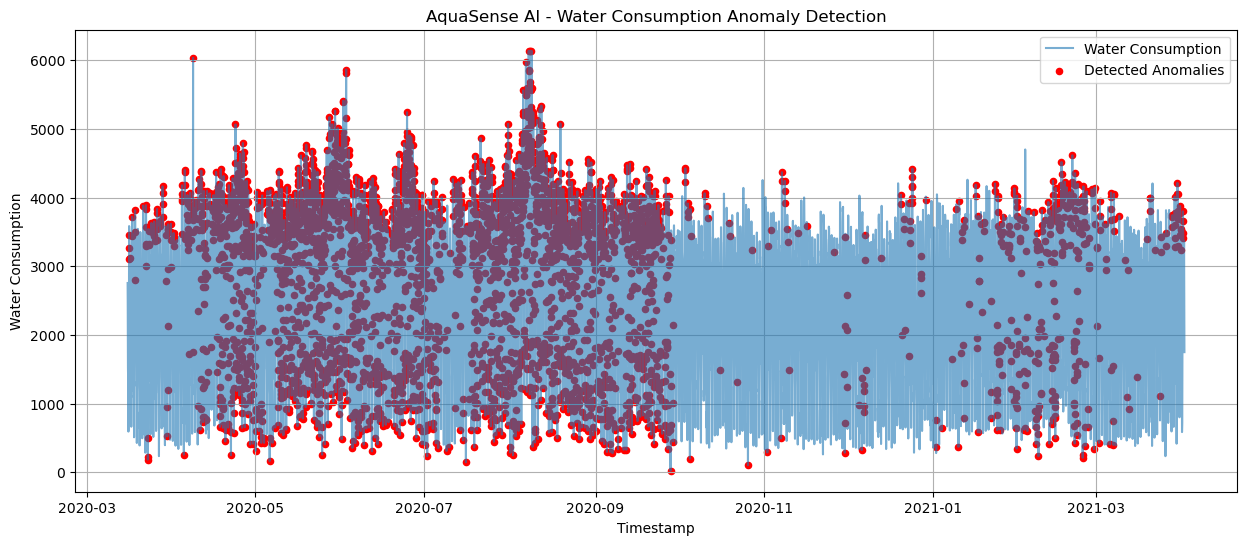

In [10]:
plt.figure(figsize=(15, 6))

normal = anomaly_results[
    anomaly_results["Anomaly"] == 1
]

anomalies = anomaly_results[
    anomaly_results["Anomaly"] == -1
]

plt.plot(
    anomaly_results["Timestamp"],
    anomaly_results["Consumption"],
    label="Water Consumption",
    alpha=0.6
)

plt.scatter(
    anomalies["Timestamp"],
    anomalies["Consumption"],
    color="red",
    label="Detected Anomalies",
    s=20
)

plt.title("AquaSense AI - Water Consumption Anomaly Detection")
plt.xlabel("Timestamp")
plt.ylabel("Water Consumption")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
# Predict anomalies in both datasets
train_predictions = iso_model.predict(X_anomaly_train)
test_predictions = iso_model.predict(X_anomaly_test)

# Calculate anomaly percentages
train_anomalies = (train_predictions == -1).sum()
test_anomalies = (test_predictions == -1).sum()

train_percentage = (train_anomalies / len(X_anomaly_train)) * 100
test_percentage = (test_anomalies / len(X_anomaly_test)) * 100

print("TRAINING DATA")
print("-------------------------")
print("Total Records:", len(X_anomaly_train))
print("Anomalies:", train_anomalies)
print("Anomaly Percentage:", round(train_percentage, 2), "%")

print("\nTESTING DATA")
print("-------------------------")
print("Total Records:", len(X_anomaly_test))
print("Anomalies:", test_anomalies)
print("Anomaly Percentage:", round(test_percentage, 2), "%")

TRAINING DATA
-------------------------
Total Records: 36691
Anomalies: 5224
Anomaly Percentage: 14.24 %

TESTING DATA
-------------------------
Total Records: 9173
Anomalies: 3832
Anomaly Percentage: 41.77 %


In [12]:
# Compare feature statistics
train_stats = X_anomaly_train.describe().T
test_stats = X_anomaly_test.describe().T

comparison = pd.DataFrame({
    "Train_Mean": train_stats["mean"],
    "Test_Mean": test_stats["mean"],
    "Train_Std": train_stats["std"],
    "Test_Std": test_stats["std"]
})

comparison["Mean_Difference_%"] = (
    (comparison["Test_Mean"] - comparison["Train_Mean"])
    / comparison["Train_Mean"].abs().replace(0, np.nan)
) * 100

display(comparison.round(2))

,Train_Mean,Test_Mean,Train_Std,Test_Std,Mean_Difference_%
Consumption,2251.03,2574.14,1001.14,1111.08,14.35
Temperature,10.81,10.87,7.74,7.88,0.53
Rain,0.05,0.05,0.37,0.38,6.65
Sun,1.66,1.79,2.85,3.02,8.24
Hour,11.50,11.51,6.92,6.92,0.06
DayOfWeek,3.00,2.99,2.00,2.00,-0.59
Lag_1,2251.01,2574.22,1001.14,1111.05,14.36
Lag_24,2250.99,2572.90,1000.98,1111.68,14.30
Rolling_Mean_24,2250.99,2573.53,230.01,326.95,14.33
Rolling_Mean_168,2250.62,2570.83,196.88,289.21,14.23


In [13]:
# Get anomaly scores
train_scores = iso_model.decision_function(X_anomaly_train)
test_scores = iso_model.decision_function(X_anomaly_test)

print("Training Score Statistics:")
print(pd.Series(train_scores).describe())

print("\nTesting Score Statistics:")
print(pd.Series(test_scores).describe())

Training Score Statistics:
count    36691.000000
mean         0.038864
std          0.040856
min         -0.191565
25%          0.019040
50%          0.045377
75%          0.067104
max          0.114506
dtype: float64

Testing Score Statistics:
count    9173.000000
mean        0.001156
std         0.060942
min        -0.206795
25%        -0.033492
50%         0.013810
75%         0.046998
max         0.112312
dtype: float64


In [14]:
# Create monthly anomaly summary
anomaly_results["Month"] = (
    anomaly_results["Timestamp"].dt.to_period("M")
)

monthly_summary = anomaly_results.groupby("Month").agg(
    Total_Records=("Anomaly", "count"),
    Anomalies=("Anomaly", lambda x: (x == -1).sum()),
    Average_Consumption=("Consumption", "mean")
)

monthly_summary["Anomaly_Percentage"] = (
    monthly_summary["Anomalies"] /
    monthly_summary["Total_Records"]
) * 100

display(monthly_summary.round(2))

,Total_Records,Anomalies,Average_Consumption,Anomaly_Percentage
Month,,,,
2020-03,389,58,2271.58,14.91
2020-04,720,411,2625.97,57.08
2020-05,744,625,2881.58,84.01
2020-06,720,621,2871.36,86.25
2020-07,744,475,2659.86,63.84
2020-08,744,709,3047.97,95.30
2020-09,720,490,2645.32,68.06
2020-10,744,19,2351.11,2.55
2020-11,720,22,2359.19,3.06


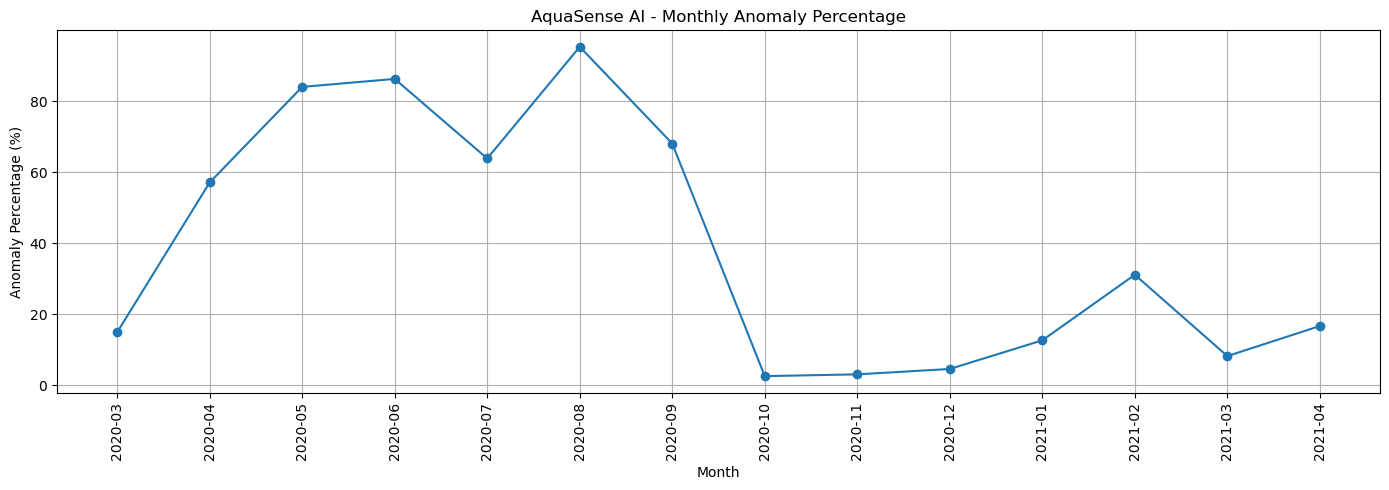

In [15]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_summary.index.astype(str),
    monthly_summary["Anomaly_Percentage"],
    marker="o"
)

plt.title("AquaSense AI - Monthly Anomaly Percentage")
plt.xlabel("Month")
plt.ylabel("Anomaly Percentage (%)")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
display(monthly_summary.round(2))

,Total_Records,Anomalies,Average_Consumption,Anomaly_Percentage
Month,,,,
2020-03,389,58,2271.58,14.91
2020-04,720,411,2625.97,57.08
2020-05,744,625,2881.58,84.01
2020-06,720,621,2871.36,86.25
2020-07,744,475,2659.86,63.84
2020-08,744,709,3047.97,95.30
2020-09,720,490,2645.32,68.06
2020-10,744,19,2351.11,2.55
2020-11,720,22,2359.19,3.06


In [17]:
# Add anomaly scores to test results
anomaly_results["Anomaly_Score"] = (
    iso_model.decision_function(X_anomaly_test)
)

# Compare normal and anomalous consumption
score_analysis = anomaly_results.groupby(
    "Anomaly_Status"
).agg(
    Record_Count=("Consumption", "count"),
    Average_Consumption=("Consumption", "mean"),
    Average_Anomaly_Score=("Anomaly_Score", "mean"),
    Minimum_Score=("Anomaly_Score", "min"),
    Maximum_Score=("Anomaly_Score", "max")
)

display(score_analysis.round(3))

,Record_Count,Average_Consumption,Average_Anomaly_Score,Minimum_Score,Maximum_Score
Anomaly_Status,,,,,
Anomaly,3832,2896.511,-0.057,-0.207,-0.000
Normal,5341,2342.849,0.043,0.000,0.112


In [18]:
# Compare monthly scores
monthly_score_analysis = anomaly_results.groupby("Month").agg(
    Average_Consumption=("Consumption", "mean"),
    Average_Score=("Anomaly_Score", "mean"),
    Anomalies=("Anomaly", lambda x: (x == -1).sum()),
    Total_Records=("Anomaly", "count")
)

monthly_score_analysis["Anomaly_Percentage"] = (
    monthly_score_analysis["Anomalies"] /
    monthly_score_analysis["Total_Records"] * 100
)

display(monthly_score_analysis.round(3))

,Average_Consumption,Average_Score,Anomalies,Total_Records,Anomaly_Percentage
Month,,,,,
2020-03,2271.576,0.044,58,389,14.910
2020-04,2625.969,-0.012,411,720,57.083
2020-05,2881.582,-0.054,625,744,84.005
2020-06,2871.361,-0.063,621,720,86.250
2020-07,2659.859,-0.016,475,744,63.844
2020-08,3047.966,-0.086,709,744,95.296
2020-09,2645.322,-0.015,490,720,68.056
2020-10,2351.113,0.055,19,744,2.554
2020-11,2359.186,0.049,22,720,3.056


In [19]:
score_analysis = anomaly_results.groupby(
    "Anomaly_Status"
).agg(
    Record_Count=("Consumption", "count"),
    Average_Consumption=("Consumption", "mean"),
    Average_Anomaly_Score=("Anomaly_Score", "mean"),
    Minimum_Score=("Anomaly_Score", "min"),
    Maximum_Score=("Anomaly_Score", "max")
)

display(score_analysis.round(3))

,Record_Count,Average_Consumption,Average_Anomaly_Score,Minimum_Score,Maximum_Score
Anomaly_Status,,,,,
Anomaly,3832,2896.511,-0.057,-0.207,-0.000
Normal,5341,2342.849,0.043,0.000,0.112


In [20]:
# Save Isolation Forest Version 1
joblib.dump(
    iso_model,
    "../models/AquaSense_Isolation_Forest_V1.pkl"
)

joblib.dump(
    anomaly_features,
    "../models/AquaSense_Anomaly_Features_V1.pkl"
)

print("Version 1 model saved successfully!")

Version 1 model saved successfully!


In [21]:
# Create a copy of the anomaly dataset
X_anomaly_v2 = X_anomaly.copy()

# Add cyclical seasonal features
X_anomaly_v2["Month_sin"] = np.sin(
    2 * np.pi * df["Month"] / 12
)

X_anomaly_v2["Month_cos"] = np.cos(
    2 * np.pi * df["Month"] / 12
)

print("Version 2 Features Shape:", X_anomaly_v2.shape)
display(X_anomaly_v2.head())

Version 2 Features Shape: (45864, 12)


,Consumption,Temperature,Rain,Sun,Hour,DayOfWeek,Lag_1,Lag_24,Rolling_Mean_24,Rolling_Mean_168,Month_sin,Month_cos
0,1025,5.5,0.0,0,0,4,1653.0,1007.0,1999.416667,1956.035714,0.5,0.866025
1,605,5.6,0.0,0,1,4,1025.0,624.0,2000.166667,1953.327381,0.5,0.866025
2,358,5.6,0.0,0,2,4,605.0,384.0,1999.375000,1948.821429,0.5,0.866025
3,277,5.4,0.0,0,3,4,358.0,217.0,1998.291667,1943.238095,0.5,0.866025
4,336,5.1,0.0,0,4,4,277.0,287.0,2000.791667,1938.363095,0.5,0.866025


In [22]:
# Split Version 2 data chronologically
split_index = int(len(X_anomaly_v2) * 0.80)

X_v2_train = X_anomaly_v2.iloc[:split_index]
X_v2_test = X_anomaly_v2.iloc[split_index:]

print("Version 2 Training Shape:", X_v2_train.shape)
print("Version 2 Testing Shape:", X_v2_test.shape)

Version 2 Training Shape: (36691, 12)
Version 2 Testing Shape: (9173, 12)


In [23]:
iso_model_v2 = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

iso_model_v2.fit(X_v2_train)

print("Isolation Forest Version 2 trained successfully!")

Isolation Forest Version 2 trained successfully!


In [24]:
# Predict anomalies on Version 2 test data
v2_predictions = iso_model_v2.predict(X_v2_test)

# Get anomaly scores
v2_scores = iso_model_v2.decision_function(X_v2_test)

# Create Version 2 results
anomaly_results_v2 = df.iloc[split_index:].copy()

anomaly_results_v2["Anomaly"] = v2_predictions
anomaly_results_v2["Anomaly_Score"] = v2_scores

anomaly_results_v2["Anomaly_Status"] = (
    anomaly_results_v2["Anomaly"].map({
        1: "Normal",
        -1: "Anomaly"
    })
)

display(
    anomaly_results_v2[
        ["Timestamp", "Consumption", "Anomaly",
         "Anomaly_Status", "Anomaly_Score"]
    ].head(20)
)

,Timestamp,Consumption,Anomaly,Anomaly_Status,Anomaly_Score
36691,2020-03-15 19:00:00,2755,1,Normal,0.055974
36692,2020-03-15 20:00:00,2474,1,Normal,0.048326
36693,2020-03-15 21:00:00,1759,1,Normal,0.030511
36694,2020-03-15 22:00:00,1515,1,Normal,0.010416
36695,2020-03-15 23:00:00,1412,1,Normal,0.005817
36696,2020-03-16 00:00:00,1509,1,Normal,0.016931
36697,2020-03-16 01:00:00,1136,1,Normal,0.021992
36698,2020-03-16 02:00:00,591,1,Normal,0.010395
36699,2020-03-16 03:00:00,735,1,Normal,0.017970
36700,2020-03-16 04:00:00,1210,1,Normal,0.022815


In [25]:
# Count anomalies in both versions
v1_anomalies = (iso_model.predict(X_anomaly_test) == -1).sum()
v2_anomalies = (v2_predictions == -1).sum()

v1_percentage = v1_anomalies / len(X_anomaly_test) * 100
v2_percentage = v2_anomalies / len(X_v2_test) * 100

comparison = pd.DataFrame({
    "Model": ["Isolation Forest V1", "Isolation Forest V2"],
    "Anomalies": [v1_anomalies, v2_anomalies],
    "Normal_Records": [
        len(X_anomaly_test) - v1_anomalies,
        len(X_v2_test) - v2_anomalies
    ],
    "Anomaly_Percentage": [
        round(v1_percentage, 2),
        round(v2_percentage, 2)
    ]
})

display(comparison)

,Model,Anomalies,Normal_Records,Anomaly_Percentage
0,Isolation Forest V1,3832,5341,41.77
1,Isolation Forest V2,4516,4657,49.23


In [26]:
# Calculate Version 1 scores
v1_scores = iso_model.decision_function(X_anomaly_test)

# Calculate Version 2 scores
v2_scores = iso_model_v2.decision_function(X_v2_test)

# Compare score distributions
score_comparison = pd.DataFrame({
    "Model": ["Version 1", "Version 2"],
    "Average_Score": [
        v1_scores.mean(),
        v2_scores.mean()
    ],
    "Median_Score": [
        np.median(v1_scores),
        np.median(v2_scores)
    ],
    "Minimum_Score": [
        v1_scores.min(),
        v2_scores.min()
    ],
    "Maximum_Score": [
        v1_scores.max(),
        v2_scores.max()
    ]
})

display(score_comparison.round(4))

,Model,Average_Score,Median_Score,Minimum_Score,Maximum_Score
0,Version 1,0.0012,0.0138,-0.2068,0.1123
1,Version 2,-0.0107,0.0012,-0.1927,0.0899


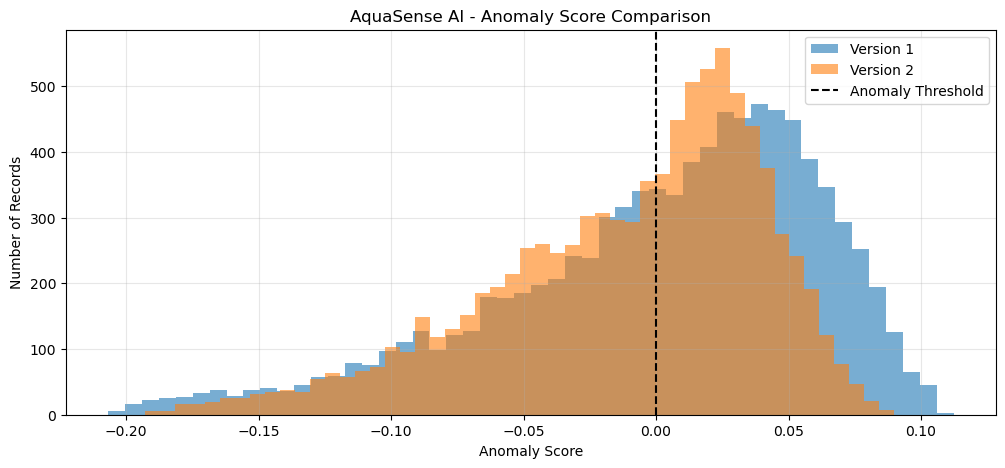

In [27]:
plt.figure(figsize=(12, 5))

plt.hist(v1_scores, bins=50, alpha=0.6, label="Version 1")
plt.hist(v2_scores, bins=50, alpha=0.6, label="Version 2")

plt.axvline(0, color="black", linestyle="--",
            label="Anomaly Threshold")

plt.title("AquaSense AI - Anomaly Score Comparison")
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Records")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
# Add Version 1 predictions to results
anomaly_results_v2["V1_Anomaly"] = iso_model.predict(
    X_anomaly_test
)

# Add Version 2 predictions
anomaly_results_v2["V2_Anomaly"] = v2_predictions

# Create monthly comparison
monthly_comparison = anomaly_results_v2.groupby(
    anomaly_results_v2["Timestamp"].dt.to_period("M")
).agg(
    Total_Records=("V2_Anomaly", "count"),
    V1_Anomalies=("V1_Anomaly", lambda x: (x == -1).sum()),
    V2_Anomalies=("V2_Anomaly", lambda x: (x == -1).sum())
)

monthly_comparison["V1_Rate"] = (
    monthly_comparison["V1_Anomalies"] /
    monthly_comparison["Total_Records"] * 100
)

monthly_comparison["V2_Rate"] = (
    monthly_comparison["V2_Anomalies"] /
    monthly_comparison["Total_Records"] * 100
)

display(monthly_comparison.round(2))

,Total_Records,V1_Anomalies,V2_Anomalies,V1_Rate,V2_Rate
Timestamp,,,,,
2020-03,389,58,90,14.91,23.14
2020-04,720,411,467,57.08,64.86
2020-05,744,625,633,84.01,85.08
2020-06,720,621,645,86.25,89.58
2020-07,744,475,457,63.84,61.42
2020-08,744,709,735,95.30,98.79
2020-09,720,490,659,68.06,91.53
2020-10,744,19,67,2.55,9.01
2020-11,720,22,82,3.06,11.39


In [29]:
# Get training and testing anomaly scores
train_scores_v1 = iso_model.decision_function(X_anomaly_train)
test_scores_v1 = iso_model.decision_function(X_anomaly_test)

# Test different threshold percentages
threshold_percentages = [1, 5, 10]

for percentage in threshold_percentages:

    # Calculate threshold using training data
    threshold = np.percentile(
        train_scores_v1,
        percentage
    )

    # Classify test records
    calibrated_predictions = np.where(
        test_scores_v1 < threshold,
        -1,
        1
    )

    # Count anomalies
    total_anomalies = (
        calibrated_predictions == -1
    ).sum()

    anomaly_rate = (
        total_anomalies / len(calibrated_predictions)
    ) * 100

    print(f"\nThreshold: {percentage}%")
    print("Threshold Score:", round(threshold, 5))
    print("Detected Anomalies:", total_anomalies)
    print("Anomaly Percentage:", round(anomaly_rate, 2), "%")


Threshold: 1%
Threshold Score: -0.10185
Detected Anomalies: 668
Anomaly Percentage: 7.28 %

Threshold: 5%
Threshold Score: -0.03725
Detected Anomalies: 2151
Anomaly Percentage: 23.45 %

Threshold: 10%
Threshold Score: -0.01233
Detected Anomalies: 3178
Anomaly Percentage: 34.65 %


In [30]:
# Calculate the 1% threshold
threshold_1 = np.percentile(train_scores_v1, 1)

# Apply threshold to test scores
predictions_1 = np.where(
    test_scores_v1 < threshold_1,
    -1,
    1
)

# Create calibrated results
calibrated_results = df.iloc[split_index:].copy()

calibrated_results["Anomaly"] = predictions_1

# Calculate monthly anomaly statistics
monthly_calibrated = calibrated_results.groupby(
    calibrated_results["Timestamp"].dt.to_period("M")
).agg(
    Total_Records=("Anomaly", "count"),
    Anomalies=("Anomaly", lambda x: (x == -1).sum())
)

monthly_calibrated["Anomaly_Percentage"] = (
    monthly_calibrated["Anomalies"] /
    monthly_calibrated["Total_Records"] * 100
)

display(monthly_calibrated.round(2))

,Total_Records,Anomalies,Anomaly_Percentage
Timestamp,,,
2020-03,389,0,0.00
2020-04,720,36,5.00
2020-05,744,137,18.41
2020-06,720,164,22.78
2020-07,744,38,5.11
2020-08,744,285,38.31
2020-09,720,8,1.11
2020-10,744,0,0.00
2020-11,720,0,0.00


In [31]:
# Divide original training data into 80% training
# and 20% validation

validation_split = int(len(X_anomaly_train) * 0.80)

X_fit = X_anomaly_train.iloc[:validation_split]
X_validation = X_anomaly_train.iloc[validation_split:]

print("Model Training Records:", len(X_fit))
print("Validation Records:", len(X_validation))
print("Final Testing Records:", len(X_anomaly_test))

Model Training Records: 29352
Validation Records: 7339
Final Testing Records: 9173


In [32]:
# Train Version 3 Isolation Forest

iso_model_v3 = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

iso_model_v3.fit(X_fit)

print("Isolation Forest Version 3 trained successfully!")

Isolation Forest Version 3 trained successfully!


In [33]:
# Get validation anomaly scores
validation_scores = iso_model_v3.decision_function(
    X_validation
)

# Display score statistics
print("Validation Score Statistics:")
print(pd.Series(validation_scores).describe())

Validation Score Statistics:
count    7339.000000
mean        0.026875
std         0.053189
min        -0.181804
25%         0.001431
50%         0.042247
75%         0.065434
max         0.106116
dtype: float64


In [34]:
# Candidate thresholds from validation scores
threshold_options = [1, 5, 10]

for percentage in threshold_options:

    threshold = np.percentile(
        validation_scores,
        percentage
    )

    # Apply threshold to validation data
    validation_predictions = np.where(
        validation_scores < threshold,
        -1,
        1
    )

    anomalies = (validation_predictions == -1).sum()

    print(f"\nThreshold: {percentage}%")
    print("Threshold Score:", round(threshold, 5))
    print("Validation Anomalies:", anomalies)
    print(
        "Validation Anomaly Rate:",
        round(anomalies / len(X_validation) * 100, 2),
        "%"
    )


Threshold: 1%
Threshold Score: -0.14499
Validation Anomalies: 74
Validation Anomaly Rate: 1.01 %

Threshold: 5%
Threshold Score: -0.08212
Validation Anomalies: 367
Validation Anomaly Rate: 5.0 %

Threshold: 10%
Threshold Score: -0.05305
Validation Anomalies: 734
Validation Anomaly Rate: 10.0 %


In [35]:
# Get scores from the untouched test dataset
test_scores_v3 = iso_model_v3.decision_function(
    X_anomaly_test
)

results_v3 = []

for percentage in threshold_options:

    threshold = np.percentile(
        validation_scores,
        percentage
    )

    predictions = np.where(
        test_scores_v3 < threshold,
        -1,
        1
    )

    anomalies = (predictions == -1).sum()

    results_v3.append({
        "Threshold_Percentile": percentage,
        "Threshold_Score": threshold,
        "Test_Anomalies": anomalies,
        "Test_Normal": len(predictions) - anomalies,
        "Test_Anomaly_Rate": (
            anomalies / len(predictions) * 100
        )
    })

threshold_comparison_v3 = pd.DataFrame(results_v3)

display(threshold_comparison_v3.round(3))

,Threshold_Percentile,Threshold_Score,Test_Anomalies,Test_Normal,Test_Anomaly_Rate
0,1,-0.145,263,8910,2.867
1,5,-0.082,1167,8006,12.722
2,10,-0.053,2094,7079,22.828


In [36]:
# Select the 1% validation threshold
final_threshold_v3 = np.percentile(validation_scores, 1)

# Classify final test records
final_predictions_v3 = np.where(
    test_scores_v3 < final_threshold_v3,
    -1,
    1
)

# Create results dataframe
anomaly_results_v3 = df.iloc[split_index:].copy()

anomaly_results_v3["Anomaly_Score"] = test_scores_v3
anomaly_results_v3["Anomaly"] = final_predictions_v3

anomaly_results_v3["Anomaly_Status"] = (
    anomaly_results_v3["Anomaly"]
    .map({1: "Normal", -1: "Anomaly"})
)

print("Version 3 Final Results")
print("-----------------------")
print("Threshold:", round(final_threshold_v3, 5))
print("Total Records:", len(anomaly_results_v3))
print(
    "Anomalies:",
    (anomaly_results_v3["Anomaly"] == -1).sum()
)
print(
    "Normal Records:",
    (anomaly_results_v3["Anomaly"] == 1).sum()
)

Version 3 Final Results
-----------------------
Threshold: -0.14499
Total Records: 9173
Anomalies: 263
Normal Records: 8910


In [37]:
anomaly_results_v3["Month_Year"] = (
    anomaly_results_v3["Timestamp"].dt.to_period("M")
)

monthly_v3 = anomaly_results_v3.groupby(
    "Month_Year"
).agg(
    Total_Records=("Anomaly", "count"),
    Anomalies=("Anomaly", lambda x: (x == -1).sum()),
    Average_Consumption=("Consumption", "mean")
)

monthly_v3["Anomaly_Rate"] = (
    monthly_v3["Anomalies"] /
    monthly_v3["Total_Records"] * 100
)

display(monthly_v3.round(2))

,Total_Records,Anomalies,Average_Consumption,Anomaly_Rate
Month_Year,,,,
2020-03,389,0,2271.58,0.00
2020-04,720,6,2625.97,0.83
2020-05,744,59,2881.58,7.93
2020-06,720,70,2871.36,9.72
2020-07,744,8,2659.86,1.08
2020-08,744,120,3047.97,16.13
2020-09,720,0,2645.32,0.00
2020-10,744,0,2351.11,0.00
2020-11,720,0,2359.19,0.00


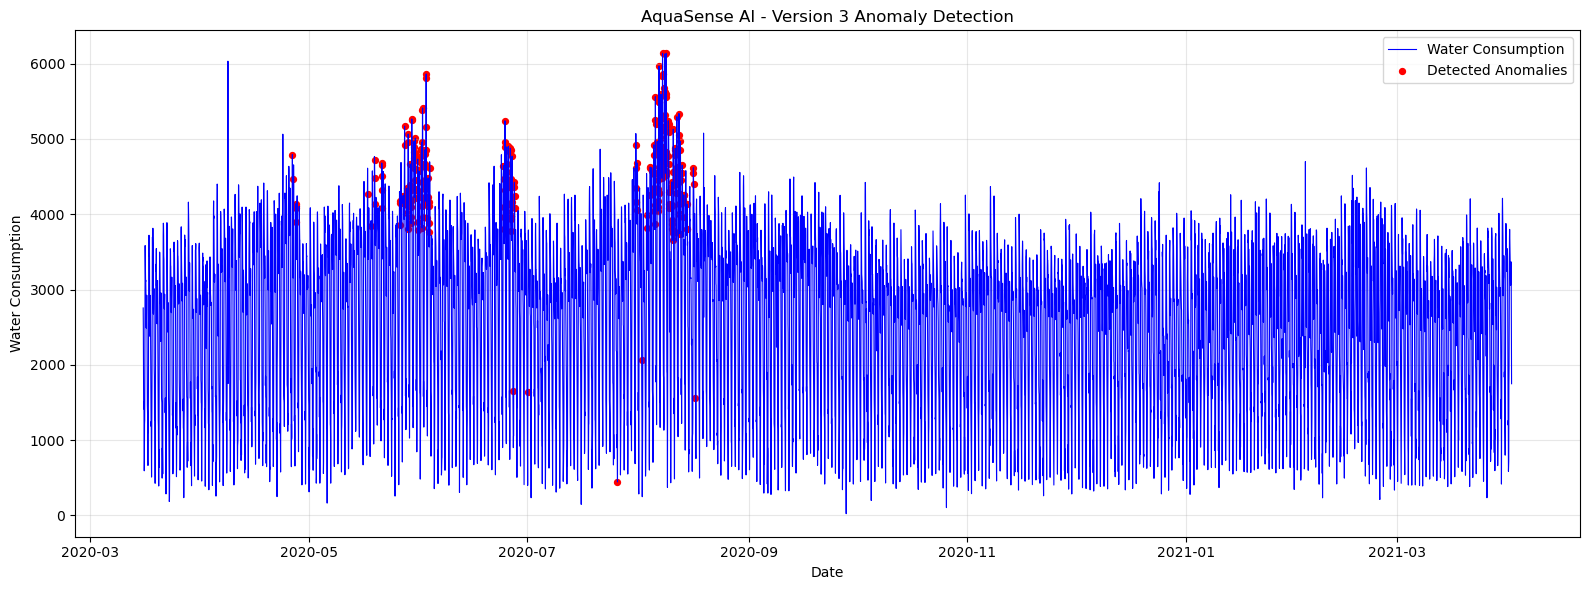

In [38]:
plt.figure(figsize=(16, 6))

plt.plot(
    anomaly_results_v3["Timestamp"],
    anomaly_results_v3["Consumption"],
    label="Water Consumption",
    color="blue",
    linewidth=0.8
)

anomalies_v3 = anomaly_results_v3[
    anomaly_results_v3["Anomaly"] == -1
]

plt.scatter(
    anomalies_v3["Timestamp"],
    anomalies_v3["Consumption"],
    color="red",
    label="Detected Anomalies",
    s=18
)

plt.title("AquaSense AI - Version 3 Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Water Consumption")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# Save Version 3 anomaly detection model

anomaly_model_bundle = {
    "model": iso_model_v3,
    "threshold": final_threshold_v3,
    "threshold_percentile": 1,
    "features": anomaly_features
}

joblib.dump(
    anomaly_model_bundle,
    "../models/AquaSense_Anomaly_Detection_Model_V3.pkl"
)

print("Version 3 model saved successfully!")

Version 3 model saved successfully!


In [40]:
anomaly_results_v3.to_csv(
    "../reports/AquaSense_Anomaly_Detection_Results.csv",
    index=False
)

print("Anomaly detection results saved successfully!")

Anomaly detection results saved successfully!


In [41]:
import os

print("Model exists:",
      os.path.exists("../models/AquaSense_Anomaly_Detection_Model_V3.pkl"))

print("Results exist:",
      os.path.exists("../reports/AquaSense_Anomaly_Detection_Results.csv"))

Model exists: True
Results exist: True
